# Naive, seasonal naive and drift baselines: what does each copy, and when does the copy fail?

**Week 4, Friday, concept notebook 2 of 4, beside chapter 2 of the deck.** The chai stall is invented: it sits at a hostel gate, and every cup in this notebook is an invented number written by the day's seeded generator. Notebook
01 found its weekly beat of 7 days and its growth of 10 percent a year.

**Who needs the answer.** The stall's owner (invented), who needs a rule a person can run on
paper before any spreadsheet opens, and Flipkart's FC planner, whose house bot is one of
these rules.

**The questions on the way.** What does each rule copy? Which wins next Sunday? What does a
yearly copy miss? What breaks when the festival moves? Where does drift do its job?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

# eight days of the invented stall, Sunday 12 to Sunday 19 January 2025
week = pd.read_csv("../data/C2_W04_D05_chai_stall_week_STUDENT.csv")
check("eight days, Sunday to Sunday", len(week) == 8 and week.weekday.iloc[0] == week.weekday.iloc[-1] == "Sun")
week                                          # every number invented

PASS eight days, Sunday to Sunday


,date,weekday,cups
0,2025-01-12,Sun,61
1,2025-01-13,Mon,103
2,2025-01-14,Tue,99
3,2025-01-15,Wed,98
4,2025-01-16,Thu,104
5,2025-01-17,Fri,101
6,2025-01-18,Sat,103
7,2025-01-19,Sun,60


## What does each rule copy?

A **baseline** is the simplest rule that could be right, and its job is to be beaten: any
cleverer forecast must do better than it. Three rules copy the past in three ways, each
one line of arithmetic. Stand on Saturday 18 January and forecast Sunday 19 January, by
hand first:

- **Naive** repeats the last day: 103.
- **Drift** takes the last value and adds the average step so far, here over the last four
  days, 98, 104, 101 and 103: 103 + (103 - 98) / 3, about 104.7.
- **Seasonal naive** copies the value one season back. The beat is 7 days, so next Sunday
  copies last Sunday: 61.

**Predict before you run.** Which rule lands nearest next Sunday's cups?

a) Naive, 103
b) Drift, about 105
c) Seasonal naive, 61
d) All three land within five cups of each other

naive: 103, miss +43
drift: 104.7, miss +44.7
seasonal naive: 61, miss +1


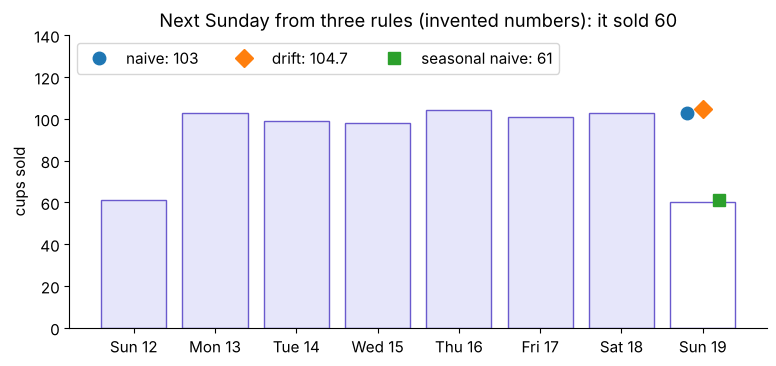

PASS by hand and by code, naive says 103
PASS by hand and by code, drift says about 104.7
PASS the seasonal naive copies last Sunday
PASS the seasonal naive lands nearest


In [2]:
def naive(history):
    return history[-1]                                        # the last value

def seasonal_naive(history, m):
    return history[-m]                                        # the value one season of m periods back

def drift(history, h=1):
    step = (history[-1] - history[0]) / (len(history) - 1)    # the average step so far
    return history[-1] + h * step                             # the line, extended h periods

seen, actual = week.cups.iloc[:7].tolist(), week.cups.iloc[-1]    # Sun 12 to Sat 18 Jan, and Sun 19 Jan
forecasts = {"naive": naive(seen), "drift": drift(seen[-4:]), "seasonal naive": seasonal_naive(seen, 7)}
for name, f in forecasts.items():
    print(f"{name}: {round(f, 1)}, miss {round(f - actual, 1):+}")
fig, ax = plt.subplots()
ax.bar(range(8), week.cups, color=["lavender"] * 7 + ["white"], edgecolor="slateblue")
for (name, f), mark, at in zip(forecasts.items(), ["o", "D", "s"], [6.8, 7.0, 7.2]):
    ax.plot(at, f, marker=mark, ls="", markersize=9, label=f"{name}: {round(f, 1)}")
ax.set_xticks(range(8), week.weekday + " " + week.date.str[8:])
ax.set_ylim(0, 140)
ax.set_ylabel("cups sold")
ax.set_title(f"Next Sunday from three rules (invented numbers): it sold {actual}")
ax.legend(ncol=3, loc="upper left")
plt.show()
check("by hand and by code, naive says 103", naive(seen) == 103)
check("by hand and by code, drift says about 104.7", round(drift(seen[-4:]), 1) == round(103 + (103 - 98) / 3, 1))
check("the seasonal naive copies last Sunday", seasonal_naive(seen, 7) == seen[0])
check("the seasonal naive lands nearest", min(forecasts, key=lambda k: abs(forecasts[k] - actual)) == "seasonal naive")

**What happened.** The answer is c. Next Sunday sold 60: naive said 103 and missed by 43,
drift said 104.7 and missed by 44.7, and the seasonal naive said 61 and missed by 1. When a
beat is strong, the plainest copy that respects it wins.

Named last, as Forecasting: Principles and Practice writes them (section 5.2, checked 13
October 2026), with T the last period a rule may see, h the periods ahead and m the
season's length:

- naive: forecast(T + h) = y(T), the last value;
- seasonal naive: forecast(T + h) = y(T + h - m), the value one season back, for h up to m;
- drift: forecast(T + h) = y(T) + h x (y(T) - y(1)) / (T - 1), the line from the first
  value to the last, extended.

## What does a yearly copy miss?

The stall (invented) has a yearly beat too. The November exam fortnight began on Wednesday
27 November 2024 at 140 cups and on Wednesday 26 November 2025 at 154. Stand on Tuesday 25
November 2025, which sold 110. Naive copies it and falls 44 cups short on the first exam
day. The yearly copy, the same weekday 364 days back, says 140 and falls 14 short, the
year's growth; times 1.10 it says 154.

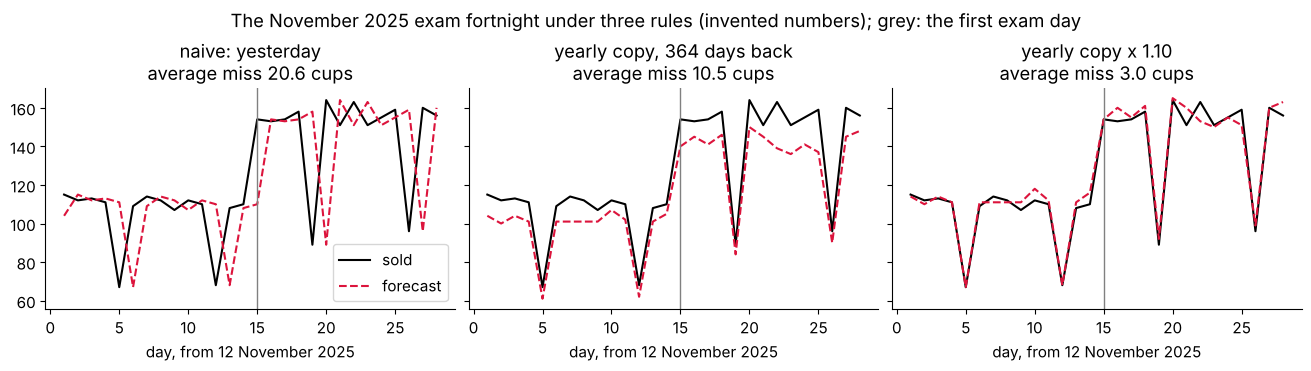

first exam day sold 154 ; naive said 110 ; the yearly copy 140 ; with growth 154
average miss over the 28 days, cups: naive: yesterday 20.6; yearly copy, 364 days back 10.5; yearly copy x 1.10 3.0
PASS naive falls more than 30 cups short on the first exam day
PASS the yearly copy with growth lands within 2 cups


In [3]:
stall = pd.read_csv("../data/C2_W04_D05_chai_stall_daily_STUDENT.csv", parse_dates=["date"])
cups = stall.set_index("date").cups
days = pd.date_range("2025-11-12", periods=28)              # the fortnight before the exams, and the exams
rules = pd.DataFrame({"naive: yesterday": cups.shift(1).loc[days],
                      "yearly copy, 364 days back": cups.shift(364).loc[days],
                      "yearly copy x 1.10": (cups.shift(364) * 1.10).round().loc[days]})
mae = {name: (rules[name] - cups.loc[days]).abs().mean() for name in rules}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, constrained_layout=True)
for ax, name in zip(axes, rules):
    ax.plot(range(1, 29), cups.loc[days].values, color="black", label="sold")
    ax.plot(range(1, 29), rules[name].values, color="crimson", ls="--", label="forecast")
    ax.axvline(15, color="grey", lw=1)                         # day 15: the first exam day, 26 November
    ax.set_title(f"{name}\naverage miss {mae[name]:.1f} cups")
    ax.set_xlabel("day, from 12 November 2025")
axes[0].legend(loc="lower right")
fig.suptitle("The November 2025 exam fortnight under three rules (invented numbers); grey: the first exam day")
plt.show()
first = pd.Timestamp("2025-11-26")
print("first exam day sold", cups[first], "; naive said", int(rules.loc[first].iloc[0]),
      "; the yearly copy", int(rules.loc[first].iloc[1]), "; with growth", int(rules.loc[first].iloc[2]))
print("average miss over the 28 days, cups: " + "; ".join(f"{name} {m:.1f}" for name, m in mae.items()))
check("naive falls more than 30 cups short on the first exam day", cups[first] - rules.loc[first].iloc[0] > 30)
check("the yearly copy with growth lands within 2 cups", abs(rules.loc[first].iloc[2] - cups[first]) <= 2)

**What happened.** Across the 28 days naive misses by 20.6 cups a day, since it copies an
ordinary day into the first exam day; the yearly copy misses by 10.5, the year's growth;
the yearly copy times 1.10 by 3.0. The copy reaches 364 days back, never a calendar year of
days, because 364 is 52 whole weeks: a Wednesday lands on a Wednesday and the weekly beat
stays in step. Finance's habit at Flipkart, "last year plus 4 percent", is this rule: the
seasonal naive times a growth factor, read as notebook 01 reads trend.

## What breaks when the festival moves?

**The plausible wrong answer.** "The yearly copy knows the season, so it is the safe rule
for Diwali." Diwali came eleven days earlier in 2025, on Monday 20 October against
Thursday 31 October 2024. The copy for Monday 20 October 2025 reads Monday 21 October 2024,
an ordinary day of 100 cups; the copy for Thursday 30 October 2025 reads Thursday 31
October 2024, Diwali day, 40 cups.

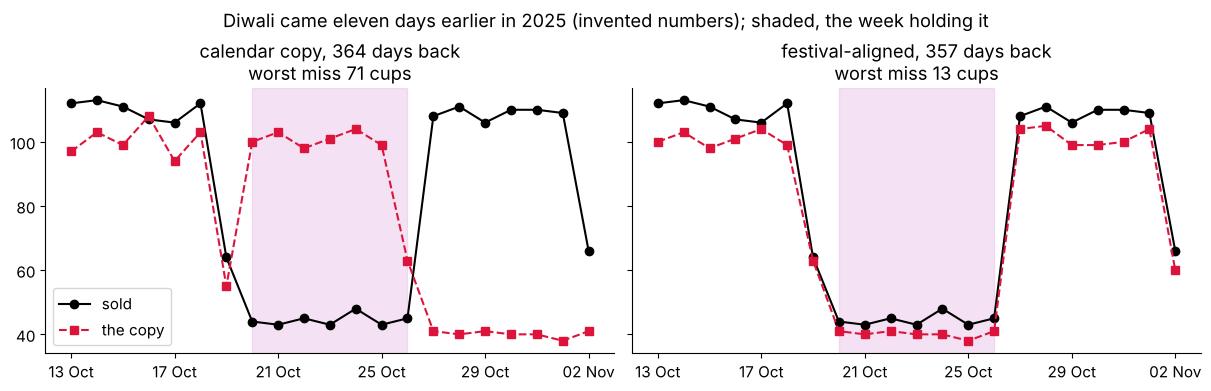

Diwali 2025, Monday 20 October: sold 44, the calendar copy said 100
the calendar copy: worst miss 71 cups, average 41.1
festival-aligned: worst miss 13 cups, average 6.5
PASS the calendar copy misses the moved festival by more than 50 cups
PASS festival-aligned misses by less than 15


In [4]:
def festival_aligned(cups, day, festival_week, gap, reach=14):
    """Near the festival, copy the day at the same distance from last year's festival week;
    elsewhere, the same weekday 364 days back."""
    near = festival_week - pd.Timedelta(days=reach) <= day < festival_week + pd.Timedelta(days=7 + reach)
    return cups[day - pd.Timedelta(days=gap if near else 364)]

week_now, week_then = pd.Timestamp("2025-10-20"), pd.Timestamp("2024-10-28")   # the Mondays of the weeks holding Diwali
gap = (week_now - week_then).days                                                # 357 days, 51 weeks
days = pd.date_range("2025-10-13", periods=21)                                   # the three weeks around Diwali's week
calendar = cups.shift(364).loc[days] - cups.loc[days]                            # the calendar copy's misses
aligned = pd.Series([festival_aligned(cups, d, week_now, gap) for d in days], index=days) - cups.loc[days]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, constrained_layout=True)
for ax, (name, miss) in zip(axes, [("calendar copy, 364 days back", calendar), (f"festival-aligned, {gap} days back", aligned)]):
    ax.plot(days, cups.loc[days], color="black", marker="o", label="sold")
    ax.plot(days, cups.loc[days] + miss, color="crimson", ls="--", marker="s", label="the copy")
    ax.axvspan(week_now, week_now + pd.Timedelta(days=6), color="plum", alpha=0.3)
    ax.set_title(f"{name}\nworst miss {miss.abs().max():.0f} cups")
    ax.set_xticks(days[::4], days[::4].strftime("%d %b"))
axes[0].legend(loc="lower left")
fig.suptitle("Diwali came eleven days earlier in 2025 (invented numbers); shaded, the week holding it")
plt.show()
print(f"Diwali 2025, Monday 20 October: sold {cups['2025-10-20']}, the calendar copy said {cups['2024-10-21']}")
print(f"the calendar copy: worst miss {calendar.abs().max():.0f} cups, average {calendar.abs().mean():.1f}")
print(f"festival-aligned: worst miss {aligned.abs().max():.0f} cups, average {aligned.abs().mean():.1f}")
check("the calendar copy misses the moved festival by more than 50 cups", calendar.abs().max() > 50)
check("festival-aligned misses by less than 15", aligned.abs().max() < 15)

**Why it is wrong.** The calendar copy misses by up to 71 cups, 41.1 a day on average
across the three weeks around Diwali's week; the festival-aligned copy by at most 13 and 6.5
on average. **The decision it misleads:** milk 70 cups short on 30 October and 56 cups too
much on Diwali itself, which sours. **The check:** the calendar. **The fix:** near the
festival, copy the day at the same distance from last year's festival, 357 days back here,
since Diwali's week came 51 weeks after 2024's. The fix is this programme's own extension of
the seasonal naive, which it calls **festival-aligned**; away from the festival it is the
plain seasonal naive.

## Where does drift do its job?

Drift draws the line from the first value to the last and extends it, so it suits a plain
climb with no beat. The stall's weekly totals (invented) carry no weekly beat, since each
total holds one of every weekday.

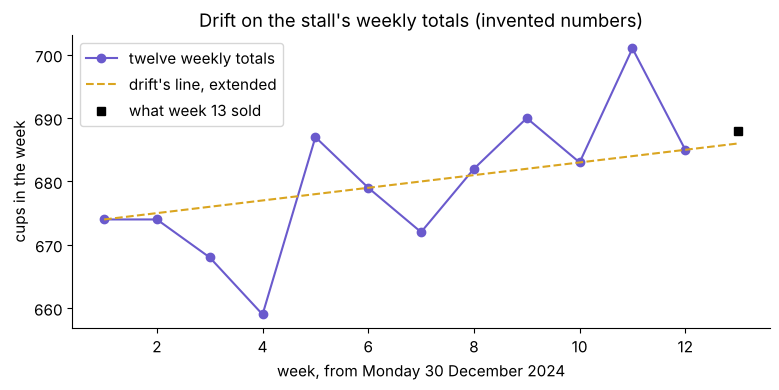

weekly totals: [674, 674, 668, 659, 687, 679, 672, 682, 690, 683, 701, 685]
drift's step: 1.0 a week; week 13: forecast 686, sold 688
PASS by hand and by code, drift says 686 for week 13


In [5]:
start = pd.Timestamp("2024-12-30")                                    # a Monday in an ordinary stretch
totals = [int(cups.loc[start + pd.Timedelta(weeks=w):start + pd.Timedelta(weeks=w, days=6)].sum()) for w in range(13)]
history, week13 = totals[:12], totals[12]
by_hand = history[-1] + (history[-1] - history[0]) / 11
fig, ax = plt.subplots()
ax.plot(range(1, 13), history, marker="o", color="slateblue", label="twelve weekly totals")
ax.plot([1, 13], [history[0], drift(history)], ls="--", color="goldenrod", label="drift's line, extended")
ax.plot(13, week13, marker="s", color="black", ls="", label="what week 13 sold")
ax.set_xlabel("week, from Monday 30 December 2024")
ax.set_ylabel("cups in the week")
ax.set_title("Drift on the stall's weekly totals (invented numbers)")
ax.legend()
plt.show()
print("weekly totals:", history)
print(f"drift's step: {(history[-1] - history[0]) / 11:.1f} a week; week 13: forecast {drift(history):.0f}, sold {week13}")
check("by hand and by code, drift says 686 for week 13", round(drift(history)) == round(by_hand) == 686)

**Your turn.** Forecast Monday 20 January 2025, the day after next Sunday, with two of the
rules. The eight rows of `week` run from Sunday 12 to Sunday 19 January (invented). Fill the
blanks, type the lines into the empty cell below and run them; the checks print PASS when
both forecasts are right, and the misses show which rule respects the beat.

```python
eight = week.cups.tolist()                    # Sunday 12 to Sunday 19 January
monday = cups["2025-01-20"]                   # what Monday 20 January sold
by_naive = naive(___)
by_season = seasonal_naive(___, 7)
print("naive misses by", by_naive - monday, "and the seasonal naive by", by_season - monday)
check("naive copies Sunday's 60 into Monday", by_naive == 60)
check("the seasonal naive copies last Monday's 103", by_season == 103)
```

## Which rules does the chapter leave?

1. A baseline is the simplest rule that could be right, and every forecast must beat it.
2. Naive repeats the last value, the seasonal naive the value one season back, and drift
   extends the line from the first value to the last.
3. When a beat is strong, the copy that respects it wins, and a yearly copy needs the year's
   growth added.
4. A festival that moves breaks every calendar copy, so copy by distance from the festival.

**In the interview.** "Naive, seasonal naive and drift are the baselines any forecast must
beat, and on seasonal data the seasonal naive is the one to beat."

In [6]:
weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
y = weekly.set_index("week_start").shipments                    # Flipkart Lucknow, the case's 104 weeks
train = y.iloc[:91]                                             # the weeks before chapter 6's hidden weeks
house_bot = y.shift(52)                                         # the seasonal naive with m = 52: the house bot
print(pd.DataFrame({"shipments": y, "seasonal naive, same week last year": house_bot}).iloc[52:55].to_string())
step = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
print(f"drift's step on the 91 training weeks: {step:.0f} shipments a week")
check("drift's step is about 70 shipments a week", round(step) == 70)
check("the house bot holds the week 52 rows up", house_bot.iloc[52] == y.iloc[0])

            shipments  seasonal naive, same week last year
week_start                                                
2025-09-29     331200                             212000.0
2025-10-06     418200                             312900.0
2025-10-13     369000                             401000.0
drift's step on the 91 training weeks: 70 shipments a week
PASS drift's step is about 70 shipments a week
PASS the house bot holds the week 52 rows up


## What did the chapter answer?

| Question | The stall's answer, in invented numbers |
|---|---|
| What does each rule copy? | Naive the last value, 103; drift the line extended, 104.7; the seasonal naive last Sunday, 61 |
| Which wins next Sunday? | The seasonal naive, a miss of 1 cup against 43 and 44.7 |
| What does a yearly copy miss? | The year's growth: 10.5 cups a day around the exams, 3.0 once it is times 1.10 |
| What breaks when the festival moves? | The calendar copy, by up to 71 cups; festival-aligned misses by at most 13 |
| Where does drift do its job? | On a plain climb: 686 for week 13 against 688 sold |

At Flipkart the seasonal naive with m = 52 is "the same week last year", which the
tournament calls the house bot; finance's rule is the house bot times 1.04; drift's step is
about 70 shipments a week. Chapter 5's notebook,
`C2_W04_D05_05_case_shape_and_baselines_STUDENT.ipynb`, runs these rules on Diwali 2025's
week; notebook 03 scores a rule on days it never saw.